In [1]:
import sys
import urllib
import zipfile
from os import path
import pandas as pd
url = u'https://archive.ics.uci.edu/ml/machine-learning-databases/00235/'
filename = 'household_power_consumption'
zipfilename = filename +'.zip'
location = url + zipfilename
if not path.isfile(zipfilename): urllib.request.urlretrieve(location, zipfilename)
zipfile.ZipFile(zipfilename).extractall()
na_values = ['?','']
fields = ['Date','Time','Global_active_power']
df = pd.read_csv(filename +'.txt', sep=';', nrows=200000,
na_values=na_values, usecols=fields)

In [2]:
import numpy as np
import time
from math import sqrt

##### Question 1 : Count the number of lines with missing values. Erase all such lines.

In [3]:
count = df.isna().any(axis=1).sum()
print("Number of lines with missing values: ",count,"\nNew dataframe without missing values:\n")

df = df.dropna()
df

Number of lines with missing values:  3732 
New dataframe without missing values:



,Date,Time,Global_active_power
0,16/12/2006,17:24:00,4.216
1,16/12/2006,17:25:00,5.360
2,16/12/2006,17:26:00,5.374
3,16/12/2006,17:27:00,5.388
4,16/12/2006,17:28:00,3.666
...,...,...,...
199995,4/5/2007,14:39:00,0.348
199996,4/5/2007,14:40:00,0.344
199997,4/5/2007,14:41:00,0.342
199998,4/5/2007,14:42:00,0.340


##### Question 2 :

In [4]:
import datetime
date_time_str = (df['Date']) + ' ' +(df['Time'])
df['DateTime'] = pd.to_datetime(date_time_str,format='%d/%m/%Y %H:%M:%S')
df = df.set_index('DateTime')
df

,Date,Time,Global_active_power
DateTime,,,
2006-12-16 17:24:00,16/12/2006,17:24:00,4.216
2006-12-16 17:25:00,16/12/2006,17:25:00,5.360
2006-12-16 17:26:00,16/12/2006,17:26:00,5.374
2006-12-16 17:27:00,16/12/2006,17:27:00,5.388
2006-12-16 17:28:00,16/12/2006,17:28:00,3.666
...,...,...,...
2007-05-04 14:39:00,4/5/2007,14:39:00,0.348
2007-05-04 14:40:00,4/5/2007,14:40:00,0.344
2007-05-04 14:41:00,4/5/2007,14:41:00,0.342


Having a DateTimeIndex allows you to easily slice and filter your data by specific time periods (like days, months, or years). It also makes it much easier to resample data (computing daily or monthly averages) and plot time series naturally.

##### Question 3 : 

Text(0.5, 0, '2007 months')

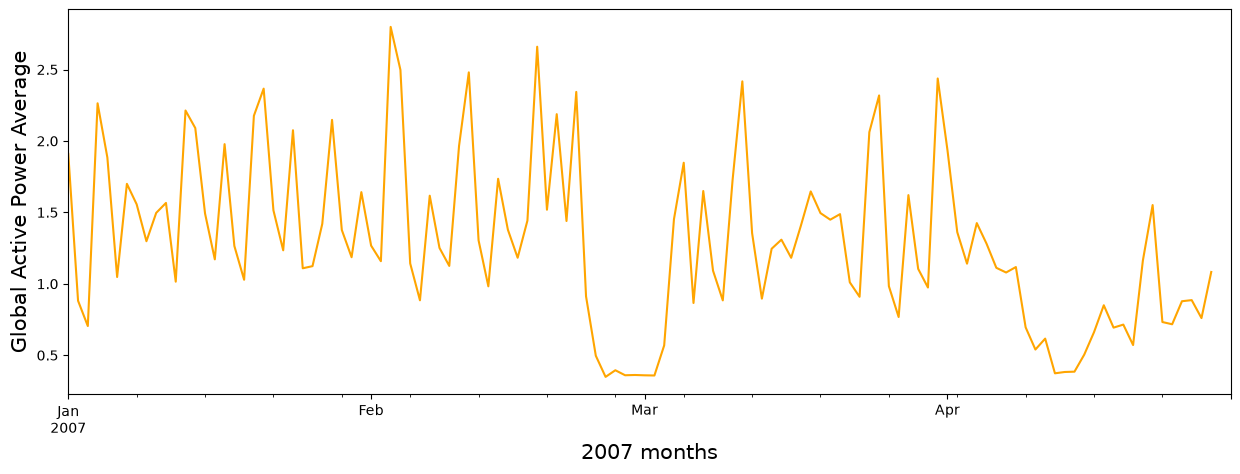

In [5]:
import matplotlib.pyplot as plt
df_jan_to_apr =df['2007-01-01':'2007-04-30'] 
df_daily_avg_gap_jan_to_apr =  df_jan_to_apr['Global_active_power'].resample('D').mean()  
df_daily_avg_gap_jan_to_apr.plot(figsize=(15,5),color='orange')
plt.ylabel('Global Active Power Average',size=15)
plt.xlabel('2007 months',size=15)


Around the end of February the consumption collapses and stays almost constant for about a week at a low level. Our explanation is that the household was away on holiday during this period. After this period, consumption goes back to intermediate values in March, then decreases again in April while the temperature rises. So two effects: less heating needed when it gets warmer, and maybe another absence of the household.

##### Question 4


In [6]:
df_temperature = pd.read_csv('TG_STAID011249.txt',sep=',',comment='#', na_values=-9999, usecols=['DATE','TG'], skipinitialspace=True)
df_temperature['TG'] = df_temperature['TG']/10

df_temperature

,DATE,TG
0,19210301,5.0
1,19210302,4.6
2,19210303,4.6
3,19210304,3.1
4,19210305,9.5
...,...,...
34878,20160827,26.6
34879,20160828,25.5
34880,20160829,20.6
34881,20160830,20.4


##### Question 5 : 


In [7]:
df_temperature['DATE'] = pd.to_datetime(df_temperature['DATE'],format='%Y%m%d')
df_temperature.set_index('DATE', inplace =True)
df_temperature


,TG
DATE,
1921-03-01,5.0
1921-03-02,4.6
1921-03-03,4.6
1921-03-04,3.1
1921-03-05,9.5
...,...
2016-08-27,26.6
2016-08-28,25.5
2016-08-29,20.6


In [8]:
daily_temp_jan_to_apr = df_temperature['2007-01-01':'2007-04-30']
daily_temp_jan_to_apr

,TG
DATE,
2007-01-01,9.6
2007-01-02,6.0
2007-01-03,6.1
2007-01-04,9.2
2007-01-05,10.0
...,...
2007-04-26,19.2
2007-04-27,20.0
2007-04-28,20.0


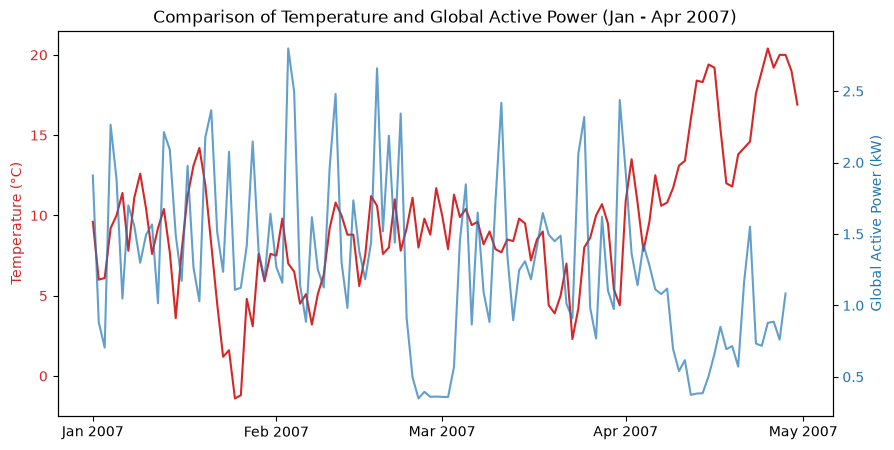

In [9]:
import matplotlib.dates as mdates

fig, ax1 = plt.subplots(figsize=(10,5))
ax1.plot(daily_temp_jan_to_apr.index,daily_temp_jan_to_apr['TG'] ,color='tab:red', label='Temperature')
ax1.xaxis.set_major_locator(mdates.MonthLocator()) # to have one per month
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y')) #to have the good format
ax1.set_ylabel('Temperature (°C)', color='tab:red')

ax1.tick_params(axis='y', labelcolor='tab:red')

ax2 = ax1.twinx()
ax2.set_ylabel('Global Active Power (kW)', color='tab:blue')
ax2.tick_params(axis='y', labelcolor='tab:blue')
ax2.plot(df_daily_avg_gap_jan_to_apr.index,df_daily_avg_gap_jan_to_apr,color='tab:blue',alpha=0.7,label='Global Active Power')
plt.title('Comparison of Temperature and Global Active Power (Jan - Apr 2007)')

plt.show()


## Exercise 2 — Linear algebra

##### Question 6 


In [10]:
def test(n, p, lamb = 1e-5):

    X = np.random.normal(0, sqrt(5), size = (n,p))
    y = np.random.uniform(-1, 1, size = n)

    Aleft = X @ X.T + lamb*np.eye(n)
    leftside = X.T @ np.linalg.solve(Aleft, y)

    Aright = X.T @ X + lamb * np.eye(p)
    rightside = np.linalg.solve(Aright, X.T @ y)

    print('close identities :', np.allclose(leftside, rightside, rtol=lamb, atol=1e-5))
    return(leftside, rightside)

test(100, 2000)
test(2000, 100)

close identities : True
close identities : True


(array([-0.00477393, -0.00599684,  0.00639632,  0.00035667, -0.00977956,
        -0.00088815,  0.00084403, -0.00877755,  0.00429944,  0.00068778,
         0.00173504, -0.00186084,  0.00236895, -0.00112867, -0.00551145,
        -0.01035507, -0.00303183,  0.00269871, -0.00889448, -0.00363163,
         0.01846666,  0.00121782, -0.00460172, -0.00737608, -0.0030302 ,
        -0.00312808,  0.00318238, -0.00367865,  0.00061226, -0.00478585,
        -0.00090529,  0.00369919,  0.00120583,  0.00483329,  0.00625426,
        -0.00217595, -0.00330534,  0.00071165, -0.00453335, -0.00635767,
        -0.00302331,  0.0036601 ,  0.00491014, -0.00665293,  0.00394368,
        -0.00604848, -0.00156471, -0.00282031,  0.00103203, -0.00022584,
        -0.00919469, -0.00639286,  0.0009242 , -0.00585788,  0.00186794,
         0.00321563, -0.00468984,  0.00955478, -0.00186692,  0.00427803,
         0.00661327,  0.00364148, -0.00376982,  0.00331537, -0.00369162,
         0.00533969, -0.00288747, -0.00249266, -0.0

##### Question 7 : 

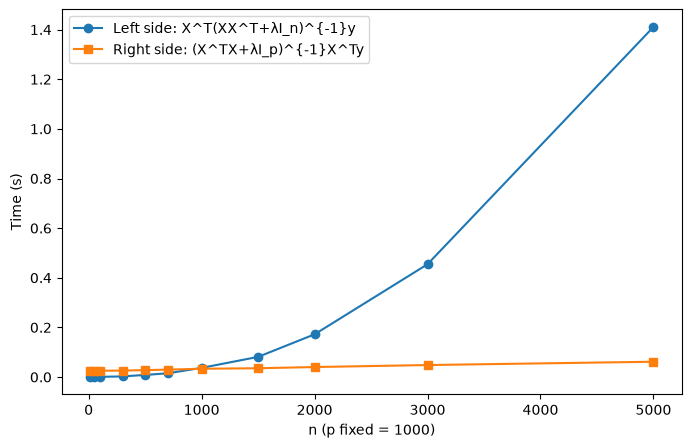

In [11]:
def timeleft(n, p, lamb=1e-5, n_repeats = 5):
    times = []
    for _ in range(n_repeats): ## so as to have several measures and be more precise rather than one isolated measure

        X = np.random.normal(0, sqrt(5) ,size = (n,p))
        y = np.random.uniform(-1, 1, size =n)

        t0 = time.perf_counter()

        Aleft = X @ X.T + lamb*np.eye(n)
        leftside = X.T @ np.linalg.solve(Aleft, y)

        times.append(time.perf_counter() - t0)
    return np.mean(times) ## returns the mean of the times 

def timeright(n, p, lamb=1e-5, n_repeats = 5):
    times = []
    for _ in range(n_repeats): ## so as to have several measures and be more precise rather than one isolated measure

        X = np.random.normal(0, sqrt(5) ,size = (n,p))
        y = np.random.uniform(-1, 1, size =n)

        t0 = time.perf_counter()

        Aright = X.T @ X + lamb * np.eye(p)
        rightside = np.linalg.solve(Aright, X.T @ y)

        times.append(time.perf_counter() - t0)
    return np.mean(times) ## returns the mean of the times

p = 1000
n_val = [10, 50, 100, 300, 500, 700, 1000, 1500, 2000, 3000, 5000]

left_times = [timeleft(z,p) for z in n_val]
right_times = [timeright(z,p) for z in n_val]

plt.figure(figsize=(8, 5))
plt.plot(n_val, left_times, 'o-', label='Left side: X^T(XX^T+λI_n)^{-1}y')
plt.plot(n_val, right_times, 's-', label='Right side: (X^TX+λI_p)^{-1}X^Ty')
plt.xlabel('n (p fixed = 1000)')
plt.ylabel('Time (s)')
plt.legend() 

When n << p, the left side is much faster because it only solves a small n x n system, whereas the right side always has to solve a p x p system  The two curves cross when n is close to p (around n=1000). When p << n, the right side is faster: for n=5000 the left side takes about 2 s against about 0.1 s for the right side, because the left side has to build and solve an n x n system, whose cost grows like n^3.

In conclusion, both formulas give the same result (Q6) but we should always choose the formulation that solve the smaller linear system: the left side if n<p, the right side if p<n.

## Exercise 3 — Random matrix spectrum

##### Question 8 : 

In [12]:

# help(np.random.exponential)


def generate_matrix(n, p, dist_name):
    # uniform dist : 
    
    if dist_name == 'uniform': 
        # Variance = (2a)^2 / 12. In order to have 2, a = sqrt(6). 
        # mean = 0 we take -a and a as minimum and max of the distribution
        a = np.sqrt(6)
        return np.random.uniform(-a, a, size=(n, p))

    elif dist_name == 'poisson': 
        # variance = mean = lambda , so for a variance = 2 we choose lambda = 2,
        # but then mean = 2 so we deduce 2 to the values in the final matrix
        lambda_val = 2 
        return np.random.poisson(lam = lambda_val, size=(n, p)) - 2

    elif dist_name == 'exponential': 
        # variance = (1/lambda)^2 = beta^2 in python where beta = 1/lambda,
        # mean = (1/lambda) = beta
        # so to have 2 as variance we choose beta = sqrt(2) -> but then mean = sqrt(2),
        # to have 0 as mean we deduce beta (sqrt(2)) to the values in the final matrix 
        beta = np.sqrt(2)
        return np.random.exponential(scale = beta, size = (n, p)) - beta


    else:
        raise ValueError("The name of the dist has to be : 'uniform', 'poisson', or 'exponential'")
        

##### Question 9 : 

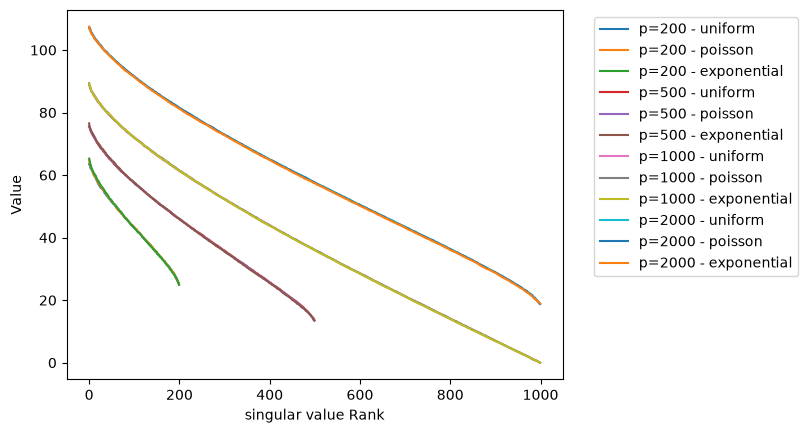

In [13]:
n = 1000
p_list = [200, 500, 1000, 2000]
dist_list = ['uniform', 'poisson', 'exponential']

for p in p_list: 
    for dist in dist_list:
        X = generate_matrix(n, p, dist)
        # X can be decomposed in X=UΣV^T with Σ= singular values
        sing_values = np.linalg.svd(X, compute_uv=False) # function to find the singular values . 
                                                         # parameter False to not have to calculate U and V (transposed) 
        plt.plot(sing_values, label = f"p={p} - {dist}")

plt.legend(bbox_to_anchor=(1.05, 1))
plt.xlabel("singular value Rank")
plt.ylabel("Value")
plt.show() 

##### Question 10 : 

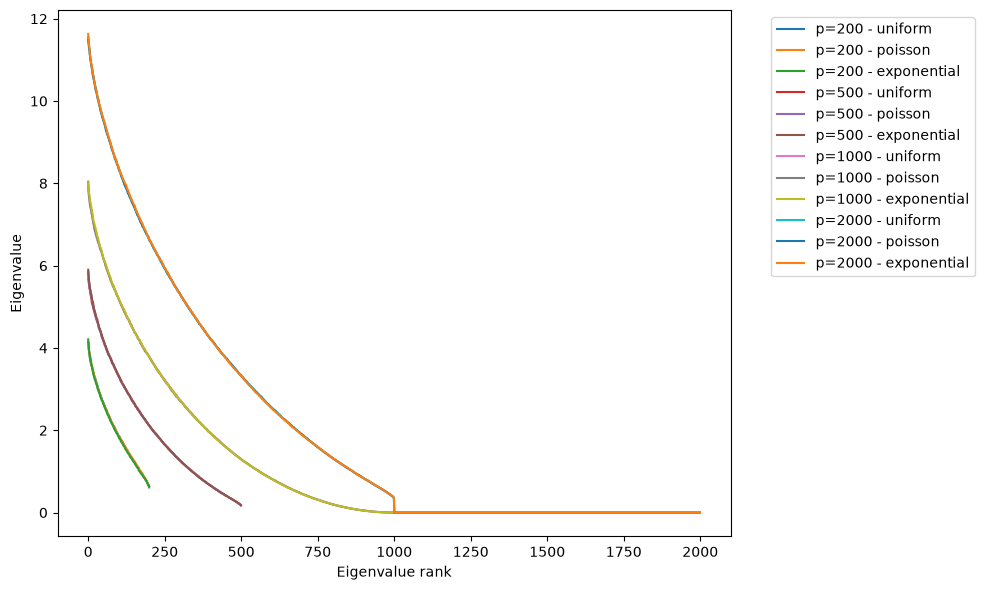

In [14]:
# we reuse the code of Q9 

n = 1000
p_list = [200, 500, 1000, 2000]
dist_list = ['uniform', 'poisson', 'exponential']
plt.figure(figsize = (10,6))
for p in p_list: 
    for dist in dist_list:
        X =generate_matrix(n, p, dist)
        matrix = (X.T @ X) / n
        eig_values = np.linalg.eigvalsh(matrix) 
        eig_values = eig_values[::-1] # we change to have the biggest values first in the graph
                                                         
        plt.plot(eig_values, label = f"p={p} - {dist}")
plt.xlabel('Eigenvalue rank')
plt.ylabel('Eigenvalue')
plt.legend(bbox_to_anchor=(1.05, 1),loc='upper left')
plt.tight_layout()
plt.show()


Just like in Question 9, the perfect overlap of the curves for each p confirms the Universality principle for the empirical covariance matrix spectrum. At a large scale (n=1000), the eigenvalue distribution of $X^\top X / n$ depends exclusively on the matrix dimensions (n/p), completely ignoring the underlying probability distribution.

Furthermore, we observe that these eigenvalues correspond to the squared singular values of $X$ divided by $n$ ($\lambda_i = \sigma_i^2 / n$). Finally, for $p = 2000 > n = 1000$, the eigenvalues drop to exactly $0$ after rank $1000$ because $\text{rank}(X^T X) \le \min(n, p) = 1000$, leaving $p - n = 1000$ zero eigenvalues.

## Exercise 4 — Power method

##### Question 11 : 

In [15]:
n = 200
p = 400

X = np.random.normal(0, np.sqrt(5), size=(n, p))

def algo1(X, T): 
    n, p = X.shape
    v = np.random.randn(p) # Generates a random vector of size p 
    for k in range(1,T+1): 
        u = (X @ v) / np.linalg.norm(X @ v)
        v = (X.T @ u) / np.linalg.norm(X.T @ u)
    return u, v 
    

##### Question 12 : 

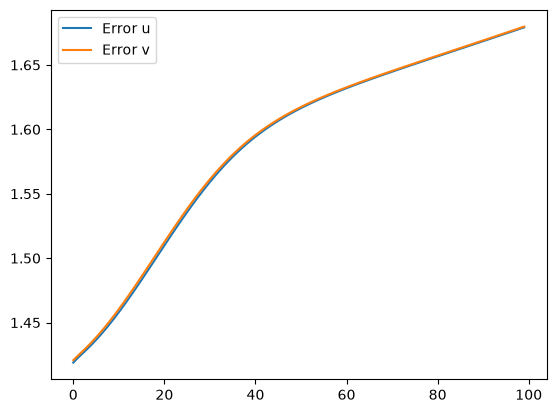

In [16]:
n = 200
p = 400
T = 100 
X = np.random.normal(0, np.sqrt(5), size=(n, p))
error_u = []
error_v = []


def algo1(X, T): 
    n,p = X.shape
    v = np.random.randn(p) # Generates a random vector of size p 
    history_u = []
    history_v = []
    for k in range(1,T+1):
        u = (X @ v) / np.linalg.norm(X @ v)
        v = (X.T @ u) / np.linalg.norm(X.T @ u)
        history_u.append(u)
        history_v.append(v)
    return history_u, history_v

U, S, Vt = np.linalg.svd(X)
u_star = U[:,0]
v_star = Vt[0,:]

history_u, history_v = algo1(X, T) # function call

for u in history_u: 
    error_u.append(np.linalg.norm(u_star - u))
for v in history_v : 
    error_v.append(np.linalg.norm(v_star - v))

plt.plot(error_u, label="Error u")
plt.plot(error_v, label="Error v")
plt.legend()
plt.show()



The Power Method successfully converges to the true leading singular vectors u* and v* computed by the SVD.

- ##### Starting error: 
    - The initial error typically starts around sqrt(2) =1.41. In high dimensions, a random initialization is highly likely to be orthogonal to the true singular vector.
- ##### Coupled convergence:
    - The errors for u and v almost perfectly overlap and decrease at the exact same rate due to their mutually dependent update equations.
  
- ##### Sign ambiguity (Limits):
    - Running the code multiple times shows the error converging to either 0 or 2. Because singular vectors are defined up to a sign shift, the algorithm converges to the exact true vector (distance of 0) or its exact opposite direction (distance of 1−(−1)=2) depending on the random starting point v0

##### Question 13 : 

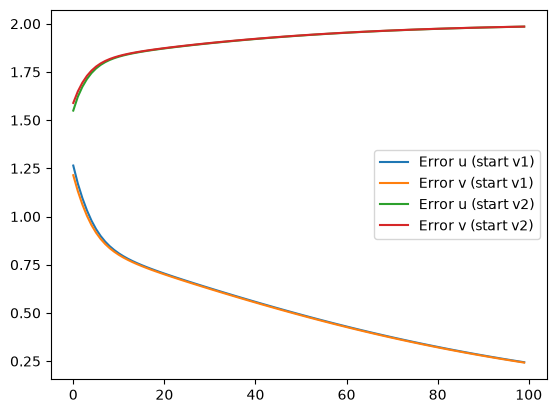

In [17]:
n = 200
p = 400
T = 100 
X = np.random.normal(0, np.sqrt(5), size=(n, p))
error_u1 = []
error_v1 = []
error_u2 = []
error_v2 = []
v1 = np.random.randn(p)
v2 = -v1

def algo1(X, T, v0): 
    n, p = X.shape
    v = v0.copy() 
    history_u = []
    history_v = []
    for k in range(1,T+1):
        u = (X @ v) / np.linalg.norm(X @ v)
        v = (X.T @ u) / np.linalg.norm(X.T @ u)
        history_u.append(u)
        history_v.append(v)
    return history_u, history_v

U, S, Vt = np.linalg.svd(X)
u_star = U[:,0]
v_star = Vt[0,:]

history_u1, history_v1 = algo1(X, T, v1) # function call
history_u2, history_v2 = algo1(X, T, v2)

# Vector v1
for u in history_u1: 
    error_u1.append(np.linalg.norm(u_star - u))
for v in history_v1 : 
    error_v1.append(np.linalg.norm(v_star - v))

# Vector -v1 
for u in history_u2: 
    error_u2.append(np.linalg.norm(u_star - u))
for v in history_v2 : 
    error_v2.append(np.linalg.norm(v_star - v))

# Show error u and v for vector v1 and -v1
plt.plot(error_u1, label="Error u (start v1)")
plt.plot(error_v1, label="Error v (start v1)")
plt.plot(error_u2, label="Error u (start v2)")
plt.plot(error_v2, label="Error v (start v2)")

plt.legend()
plt.show()



The two initializations vectors are opposite (v2 = -v1).

If an initial random vector v1 leads the algorithm to converge to the default SVD vectors (u* and v*, yielding a distance error of 0), using its opposite −v1 forces the matrix multiplication to converge to the exact opposite direction (−u* and −v*). 

Since the singular vectors are normalized (length of 1), the geometric distance between u* and −u* is exactly 2. 
Both limits are perfectly valid as they represent the exact same principal components axis.

##### Question 14 : 

Xv=σ1 u   with σ1=singular value

so : 
∣∣Xv∣∣=σ1 × ∣∣u∣∣

∣∣Xv∣∣=σ1 × 1 

∣∣Xv∣∣=σ1


In [18]:
Xv = X @ history_v2[-1]
lsv = np.linalg.norm(Xv) # largest singular value
print(f"The largest singular value = {lsv}")

The largest singular value = 76.00723650275306


##### Question 15 : 

In [19]:
u1 = history_u2[-1]
v1 = history_v2[-1]
X_new = X - lsv * np.outer(u1,v1)
v0_new = np.random.randn(p)

history_u_new, history_v_new = algo1(X_new, T, v0_new)

v2 = history_v_new[-1]
lsv2 = np.linalg.norm(X_new @ v2)

print(f"The largest singular value of X_new = {lsv2}") # the second largest singular value of X 

The largest singular value of X_new = 75.47981369351982


## Exercise 5 — Analysis of the auto-mpg dataset

##### Question 16 : 

In [20]:
url1 = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data-original"

colnames = ["mpg", "cylinders", "displacement", "horsepower", "weight", "acceleration", "model year", "origin", "car name"]
df1 = pd.read_csv(url1, sep = r"\s+",names = colnames)
df1.dropna(inplace=True) ## In the 2nd url we had to consult, the marker for missing values was NA.
df1.reset_index(drop=True, inplace=True)
df1.drop('car name', axis = 1, inplace = True)
df1

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
0,18.0,8.0,307.0,130.0,3504.0,12.0,70.0,1.0
1,15.0,8.0,350.0,165.0,3693.0,11.5,70.0,1.0
2,18.0,8.0,318.0,150.0,3436.0,11.0,70.0,1.0
3,16.0,8.0,304.0,150.0,3433.0,12.0,70.0,1.0
4,17.0,8.0,302.0,140.0,3449.0,10.5,70.0,1.0
...,...,...,...,...,...,...,...,...
387,27.0,4.0,140.0,86.0,2790.0,15.6,82.0,1.0
388,44.0,4.0,97.0,52.0,2130.0,24.6,82.0,2.0
389,32.0,4.0,135.0,84.0,2295.0,11.6,82.0,1.0
390,28.0,4.0,120.0,79.0,2625.0,18.6,82.0,1.0


In this file, missing values are marked by NA. 
\s+ splits the columns correctly.

##### Question 17 : 
We add only 2 features so the sum of the features are not equal to the intercept column for the future regression

In [21]:
df1['is American'] = (df1['origin'] == 1.0).astype(int)
df1['is European'] = (df1['origin'] == 2.0).astype(int)
df1.drop('origin', axis = 1, inplace = True)
df1

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,is American,is European
0,18.0,8.0,307.0,130.0,3504.0,12.0,70.0,1,0
1,15.0,8.0,350.0,165.0,3693.0,11.5,70.0,1,0
2,18.0,8.0,318.0,150.0,3436.0,11.0,70.0,1,0
3,16.0,8.0,304.0,150.0,3433.0,12.0,70.0,1,0
4,17.0,8.0,302.0,140.0,3449.0,10.5,70.0,1,0
...,...,...,...,...,...,...,...,...,...
387,27.0,4.0,140.0,86.0,2790.0,15.6,82.0,1,0
388,44.0,4.0,97.0,52.0,2130.0,24.6,82.0,0,1
389,32.0,4.0,135.0,84.0,2295.0,11.6,82.0,1,0
390,28.0,4.0,120.0,79.0,2625.0,18.6,82.0,1,0


##### Question 18 :

In [22]:
from sklearn.linear_model import LinearRegression

df_9 = pd.concat([
    df1[df1['is American'] == 1].sample(3, random_state=42),
    df1[(df1['is American'] == 0) & (df1['is European'] == 0)].sample(3, random_state=42),
    df1[df1['is European'] == 1].sample(3, random_state=42)    # random_state=42 so that the model year is not constant
])

y_9 = df_9['mpg']
X_9 = df_9.drop(columns=['mpg'])

model = LinearRegression(fit_intercept=True)
model.fit(X_9, y_9)

y_predicted = model.predict(X_9)
print("Intercept:", model.intercept_)
print("Model coefficients:", model.coef_)
print("True values (y) :",y_9.values)
print("Predictions (y_predicted):", y_predicted)

Intercept: 23.081151960505043
Model coefficients: [-0.42369255  0.0654165  -0.03595369 -0.01615015 -0.52609143  0.64052413
  2.735009   -1.42011545]
True values (y) : [16.  14.  18.5 33.5 24.  24.  20.3 29.  26. ]
Predictions (y_predicted): [16.  14.  18.5 33.5 24.  24.  20.3 29.  26. ]


The predictions are exactly equal to the observed values: the training error is zero. We have 8 features + 1 intercept = 9 parameters for only 9 observations.
The model does not learn a trend, it interpolates (memorizes) the 9 cars: this is overfitting.

##### Question 19 :

In [23]:
from sklearn.preprocessing import StandardScaler

y = df1['mpg']
X = df1.drop(columns='mpg')

scal = StandardScaler()               
X_scal = scal.fit_transform(X) 

model = LinearRegression(fit_intercept=True)
model.fit(X_scal, y)  
y_pred = model.predict(X_scal)

coefs = pd.Series(model.coef_, index=X.columns)
print("Intercept :" , model.intercept_)
print(coefs.sort_values(key=abs, ascending=False))

Intercept : 23.44591836734694
weight         -5.692543
model year      2.858709
displacement    2.506019
is American    -1.381313
cylinders      -0.834272
horsepower     -0.699009
acceleration    0.217956
is European    -0.084525
dtype: float64


According to the model's coefficients, the variable that best explains gasoline consumption is the weight (highest absolute coefficient), followed by the model year and displacement. The negative coefficient for weight logically indicates that heavier cars have lower fuel efficiency.

Why normalization is strictly required: If the variables were not standardized, their coefficients would be entirely dependents on their original units. For example, a car's weight is in the thousands (ex :3500 lbs), while cylinders are single digits (ex : 4 or 6). Without scaling, the model would assign a tiny coefficient to 'weight' and a massive coefficient to 'cylinders' simply to balance the mathematical equations, making it impossible to compare their true impact. By normalizing (mean=0,variance=1), all features are put on the exact same playing field, allowing us to use the absolute values of the coefficients as a direct measure of feature importance.

#### Question 20

In [24]:
from sklearn.pipeline import Pipeline

pipe = Pipeline([('scaler', StandardScaler()), ('model', LinearRegression())])   
pipe.fit(X, y)

new_car = pd.DataFrame([{ 
    'cylinders': 6,
    'displacement': 225,
    'horsepower': 100,
    'weight': 3233,
    'acceleration': 15.4,
    'model year': 117, 
    'is American': 1,
    'is European': 0
}])

Cunsumption_new_car = pipe.predict(new_car)

print('Cunsumption_new_car = ', Cunsumption_new_car[0])

Cunsumption_new_car =  53.11965663639701


The predicted consumption for this new car is approximately 53.11 mpg. This result is highly coherent: our linear model previously identified the model year as a strong positive driver for fuel eficiency. Since the training data spans from 1970 to 1982, evaluating a car from 2017 (encoded as 117) forces the model to extrapolate. It logically translates decades of technological improvements into a significantly higher miles-per-gallon performance compared to the older vehicles in the dataset. The use of a Pipeline ensured that the new raw data was perfectly standardized using the exact same scaling parameters as the training set before making the predictions.

However, from a physical standpoint, 53.11 mpg (around 4.4 L/100 km) is unrealistically optimistic for a 6-cylinder, 3233 lbs American car. This highlights the limitation of linear extrapolation: the model assumes the steep linear efficiency gains observed during the 1970s oil crisis continued at the exact same constant rate for 35 years.